# 2주차 · 예측하기 전과 평가할 때
### 자료 계약 → 분할 → 훈련 통계 → 예측 → 평가

새로 만든 센서 기록으로 모델이 **처음 보는 개체**의 이상 여부를 예측합니다. 각 행의 뜻과 예측 시점에 보이는 열을 정하고, 독립된 개체를 나눈 뒤, 알려진 훈련 행으로만 결측을 채우고 표준화를 배웁니다. 고정 규칙과 기준 모델의 예측을 혼동행렬로 확인하고, 행별 점수와 개체별 점수의 차이도 계산합니다.

자료와 숫자는 모두 독자 합성 예제이며 실제 센서 성능이나 대회 문항이 아닙니다. Python 변수·조건문·반복문·함수·리스트와 1주차 표·평균을 선수로 합니다. AI를 미리 배우지는 않아도 됩니다. 작고 일부러 불균형하게 만든 이 자료의 점수로 실제 성능을 추정하지 않습니다.

## 오늘의 목표와 사용법

1. 예측 시점, 한 행·특성·정답·미상의 뜻과 출력 순서를 말한다.
2. 개체 또는 시간에 맞게 분할하고, 훈련·검증·최종 테스트의 역할을 구별한다.
3. `fit`이 배운 평균·표준편차를 수식과 코드로 확인하고, 검증에는 `transform`만 적용한다.
4. 양성 기준을 정해 TP/FP/FN/TN과 정확도·정밀도·재현율을 계산하고 분모 0을 해석한다.
5. 새 자료에서 같은 결정을 이유와 함께 독립적으로 적용한다.

Jupyter 또는 Colab의 Python 3에서 NumPy, pandas, scikit-learn 1.3 이상, Matplotlib이 필요합니다. 1.3 이상은 이 노트북에서 `zero_division=np.nan`을 사용하기 위해 필요합니다. 모두 준비된 환경에서 노트북을 열고 첫 셀부터 **Shift+Enter**로 순서대로 실행하세요. 저장은 Ctrl+S(맥은 ⌘S), 전체 재실행은 Kernel → Restart Kernel and Run All Cells입니다. 각 질문은 실행 전에 답과 이유를 쓰고, 답안 칸에 받은 도움을 기록합니다. 빈 코드 칸은 학생이 작성하는 곳입니다.

## 1. 먼저 자료 계약을 읽습니다 · 이론

### 무슨 순간에 무엇을 아나요?

센서가 한 번 측정한 **직후** 이상 알림이 필요한 상황을 가정합니다. 한 행은 한 개체에서 한 번 측정한 기록입니다. 예측 시점에 개체 번호와 센서값이 제공되고 센서값이 비어 있을 수 있습니다. 전문가의 판정은 예측 **후**에만 정답으로 확인됩니다. 같은 개체가 여러 번 등장할 수 있습니다.

| 열 | 뜻 | 예측에 사용할 역할 |
|---|---|---|
| `row_id` | 기록 식별자 | 결과 순서 확인용, 모델 입력 아님 |
| `group` | 개체 식별자 | 새 개체 분할·평가 확인용, 모델 입력 아님 |
| `reading` | 측정 직후 예측 시점에 제공되는 센서값(합성 단위 u), 없으면 결측 | 유일한 수치 특성 $x$ |
| `label` | 나중에 확인한 판정: `+1` 이상, `-1` 정상, `0` 판정 미상 | 훈련·검증 정답 $y$, 입력 특성 아님 |

`reading`의 결측은 **측정값이 기록되지 않음**입니다. 숫자 `0`과 다릅니다. `label=0`은 이 자료의 **정답 미상**으로, 명시된 정상 `-1`이 아닙니다. 예측은 각 입력 행 순서대로 `-1` 또는 `+1` 하나씩 만듭니다. 진단 후에 생긴 수리 여부나 전문가 판정 자체를 입력에 넣으면 예측 시점에 없으므로 누수입니다.

이 정의는 이 예제의 약속입니다. 다른 과제에서는 문서가 제공한다고 밝힌 예측 시점의 입력과 허용된 자료 활용 방식을 먼저 확인해야 합니다. 모든 과제에서 라벨 `0`이 미상인 것은 아닙니다.

### 훈련·검증·최종 테스트를 나누는 이유

- **훈련**: 전처리의 통계량과 모델을 학습합니다.
- **검증**: 훈련에 사용하지 않은 정답으로 후보 모델·설정을 비교하고 선택합니다. 여러 번 선택에 쓰면 검증에도 맞춰질 수 있습니다.
- **최종 테스트**: 모든 후보·설정 선택을 끝내고 고정한 뒤, 처음 보는 자료에 대한 마지막 평가를 한 번 합니다. 이번 수업의 테스트 정답과 점수는 열지 않습니다.

처음 보는 개체의 성능을 보려면 같은 개체의 행이 서로 다른 묶음에 새지 않게 나눕니다. 행 ID가 다르더라도 같은 개체라면 독립된 새 개체가 아닙니다. 미래 예측이라면 시점 순서도 중요하므로 과거로 학습하고 미래를 평가해야 합니다. 어떤 과제는 그룹과 시간을 함께 고려해야 하며, 그때 분할이 가능한지 직접 검사합니다. 작은 자료에서는 그룹 분리·시간 순서·정확한 클래스 비율을 **모두 동시에 만족하지 못할 수 있습니다**. 목적과 제약을 보고 우선순위와 한계를 기록합니다. 무작위 행 분할만으로 이 조건들이 보장되지는 않습니다.

라벨의 공개 여부는 과제마다 다릅니다. 예컨대 어떤 공개 개발용 test에는 정답이 있어도 실제 제출 실행에는 없을 수 있습니다. 이 수업에서는 최종 테스트 정답을 보류하며, 문제 명세에 따라 실제 제공 입력과 출력 요구를 따릅니다.

### 분할할 표

이번 수업의 작은 예제에서는 A·B만 훈련, C·D는 검증에 사용합니다. E·F는 최종 테스트 개체의 자리 표시이며 자료와 정답은 아직 만들어지지 않았습니다. 훈련 A/B의 두 클래스 수가 우연히 같지만 그룹을 나눌 때마다 같은 비율이 보장되는 것은 아닙니다.

| 행 | 개체 | reading(u) | label |
|---|---|---:|---:|
| a1 | A | 2 | -1 |
| a2 | A | 4 | -1 |
| b1 | B | 6 | +1 |
| b2 | B | 결측 | +1 |
| b3 | B | 8 | 0(미상) |
| c1 | C | 20 | +1 |
| c2 | C | 결측 | +1 |
| d1 | D | 10 | -1 |
| d2 | D | 12 | -1 |

같은 합성 원본에는 **추가 훈련 후보** G/H도 있습니다. 아래 네 행은 이번 A/B 손계산이나 `fit`에는 넣지 않습니다. 이 표와 위 표의 열은 같습니다.

| 행 | 개체 | reading(u) | label |
|---|---|---:|---:|
| g1 | G | 2 | -1 |
| g2 | G | 4 | +1 |
| h1 | H | 4 | -1 |
| h2 | H | 6 | +1 |

4주차에 A/B/G/H를 훈련 후보로 함께 사용한다면 정답이 알려진 행을 고른 뒤 전처리와 모델을 **다시 fit**하고, 기준 모델도 같은 조건에서 다시 계산합니다. C/D는 검증에 남기고 E/F는 생성 전 자리 표시로 둡니다. 전체 원본은 같아도 이번 수업과 4주차의 훈련 행과 `fit` 상태는 다릅니다. 교차검증은 각 훈련 fold에서 전처리를 새로 fit해야 하며, 이 작은 합성 자료는 안정적인 성능 추정용이 아닙니다.

**예상**: b3을 정상 사례로 세어도 될까요? a1과 a2가 다른 행이니 하나는 훈련, 하나는 검증으로 보내도 새 개체 평가일까요? `row_id`의 순서가 달라지면 예측을 어떻게 원래 행과 연결할까요?

이 예제의 지도학습 파이프라인은 **정답이 알려진 훈련 행만** 특성 통계와 모델의 `fit`에 사용합니다. b3은 미상이라 제외합니다. 별도의 반지도·비지도 방법이 미상 라벨 행의 **입력 특성**을 쓰는 것은 과제 명세와 방법이 허용할 때 가능합니다. 미상을 `-1`로 바꾸는 것과는 다릅니다.

In [2]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve

records = pd.DataFrame([
    ("a1", "A", 2, -1), ("a2", "A", 4, -1),
    ("b1", "B", 6, 1), ("b2", "B", np.nan, 1), ("b3", "B", 8, 0),
    ("c1", "C", 20, 1), ("c2", "C", np.nan, 1),
    ("d1", "D", 10, -1), ("d2", "D", 12, -1),
], columns=["row_id", "group", "reading", "label"])
# 같은 원본의 추가 훈련 후보. 이번 수업의 A/B fit에는 넣지 않습니다.
additional_train = pd.DataFrame([
    ("g1", "G", 2, -1), ("g2", "G", 4, 1),
    ("h1", "H", 4, -1), ("h2", "H", 6, 1),
], columns=records.columns)
course_records = pd.concat([records, additional_train], ignore_index=True)
train_4w = course_records[course_records["group"].isin(["A", "B", "G", "H"])].copy()
known_train_4w = train_4w[train_4w["label"].isin([-1, 1])].copy()
assert course_records["row_id"].is_unique
assert set(train_4w["group"]).isdisjoint({"C", "D"})

train = records[records["group"].isin(["A", "B"])].copy()
validation = records[records["group"].isin(["C", "D"])].copy()
known_train = train[train["label"].isin([-1, 1])].copy()
assert set(train["group"]).isdisjoint(set(validation["group"]))
assert records["row_id"].is_unique
print("훈련 개체:", sorted(train["group"].unique()))
print("검증 개체:", sorted(validation["group"].unique()))
print("fit에 쓰는 훈련 행:", known_train["row_id"].tolist())
print("정답 미상으로 제외한 훈련 행:", train.loc[train["label"] == 0, "row_id"].tolist())
print("검증 출력 순서:", validation["row_id"].tolist())
print("4주 추가 훈련 후보 행:", additional_train["row_id"].tolist())

훈련 개체: ['A', 'B']
검증 개체: ['C', 'D']
fit에 쓰는 훈련 행: ['a1', 'a2', 'b1', 'b2']
정답 미상으로 제외한 훈련 행: ['b3']
검증 출력 순서: ['c1', 'c2', 'd1', 'd2']
4주 추가 훈련 후보 행: ['g1', 'g2', 'h1', 'h2']


## 2. `fit`은 훈련에서 규칙을 배우고 `transform`은 그 규칙을 적용합니다

### 손으로 먼저 구하기

알려진 훈련 행의 `reading`은 `[2, 4, 6, 결측]`입니다. 관측된 세 값만으로 평균을 구하면 $(2+4+6)/3=4\,u$입니다. 훈련의 결측을 4로 채우면 `[2, 4, 6, 4]`가 됩니다. 이 네 수의 평균은 $\mu=4\,u$이고, 여기서 쓰는 모집단 표준편차는

$$\sigma=\sqrt{\frac{(2-4)^2+(4-4)^2+(6-4)^2+(4-4)^2}{4}}=\sqrt{2}\,u.$$

특성값 $x$에 대한 표준화는 $z=(x-\mu)/\sigma$입니다. 따라서 $x=6\,u$는 $z=\sqrt{2}$, 결측은 훈련 평균 4로 대체되어 $z=0$입니다. 이 $z$는 단위가 없습니다. 표준편차가 0인 상수 특성에서는 위 나눗셈을 그대로 적용할 수 없으니 라이브러리의 상수 특성 처리와 과제 조건을 확인합니다.

이제 잘못된 방법을 상상해 보세요. 검증의 관측값 20, 10, 12까지 평균에 섞으면 $(2+4+6+20+10+12)/6=9\,u$가 됩니다. **평가할 자료가 학습한 결측 대체값을 바꿨으므로** 공정한 새 자료 평가가 아닙니다. 9가 4보다 크다는 사실이 모델 성능이 꼭 좋아진다는 뜻은 아닙니다. 이 사례에서 검증 입력을 전처리의 `fit`에 섞어 평가 정보가 학습에 들어간 점이 문제입니다. 검증 결과로 후보를 선택하는 것은 검증 자료의 정해진 역할입니다.

In [3]:
preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])
X_train = known_train[["reading"]]
X_val = validation[["reading"]]
train_z = preprocess.fit_transform(X_train)  # 훈련에서만 평균과 스케일을 배움
val_z = preprocess.transform(X_val)          # 배운 규칙을 그대로 사용
print("훈련 평균 대체값:", preprocess.named_steps["imputer"].statistics_[0])
print("대체 후 훈련 평균과 표준편차:", preprocess.named_steps["scaler"].mean_[0],
      round(preprocess.named_steps["scaler"].scale_[0], 6))
print("훈련 z:", np.round(train_z[:, 0], 3).tolist())
print("검증 행과 z:", list(zip(validation["row_id"], np.round(val_z[:, 0], 3).tolist())))

# 일부러 틀린 반례: 검증 입력까지 fit에 넣음. 아래 결과는 정답 모델에 쓰지 않음.
leaky_imputer = SimpleImputer(strategy="mean").fit(pd.concat([X_train, X_val]))
print("틀린 대체값(검증 입력 포함):", leaky_imputer.statistics_[0])
assert np.isclose(preprocess.named_steps["imputer"].statistics_[0], 4)
assert np.isclose(leaky_imputer.statistics_[0], 9)

훈련 평균 대체값: 4.0
대체 후 훈련 평균과 표준편차: 4.0 1.414214
훈련 z: [-1.414, 0.0, 1.414, 0.0]
검증 행과 z: [('c1', 11.314), ('c2', 0.0), ('d1', 4.243), ('d2', 5.657)]
틀린 대체값(검증 입력 포함): 9.0


`fit`은 수치를 기억합니다. `fit_transform(X_train)`은 훈련으로 배우고 훈련을 변환하며, `transform(X_val)`은 기억한 값을 검증에 적용합니다. `fit_transform(X_val)`로 다시 배우면 다른 잣대가 생기고 평가 정보가 흘러듭니다. 위의 누수 코드는 차이를 보여 주는 **반례**이며 모델에 연결하지 않았습니다. 특성 선택 등 다른 학습형 전처리도 분할 후 훈련으로 배웁니다. 파이프라인은 같은 순서를 재사용하고 실수를 줄이는 도구입니다.

**생각하기**: 검증 `c2`의 결측을 20이나 검증 평균이 아니라 4로 대체한 이유는 무엇일까요? b3의 입력 8을 함께 평균 낼 수 있는 별도 방법을 설계하려면 어떤 자료 계약과 학습 방법을 먼저 정해야 할까요?

## 3. 양성을 정하고 예측을 셉니다 · 비코딩

이 예제는 `+1`을 양성(이상)으로 정합니다. **참/거짓은 정답과 맞는지**, 양성/음성은 **예측이 어느 쪽인지**를 나타냅니다.

| 실제 ↓ / 예측 → | -1 정상 | +1 이상 |
|---|---:|---:|
| -1 정상 | TN: 정상이라고 맞힘 | FP: 정상인데 이상이라고 잘못 알림 |
| +1 이상 | FN: 이상인데 놓침 | TP: 이상이라고 맞힘 |

검증 c1, c2, d1, d2에 대한 예측이 순서대로 `[+1, -1, +1, +1]`이라면 TP=1(c1), FN=1(c2), FP=2(d1,d2), TN=0입니다. 각 분모에 누구를 세는지 먼저 말합니다.

$$\text{정확도}=\frac{TP+TN}{TP+TN+FP+FN}=\frac{1}{4}.$$
$$\text{정밀도}=\frac{TP}{TP+FP}=\frac{1}{3}\quad\text{(이상이라 예측한 행 중 맞은 비율)}.$$
$$\text{재현율}=\frac{TP}{TP+FN}=\frac{1}{2}\quad\text{(실제 이상 행 중 찾아낸 비율)}.$$

FP가 늘면 정밀도의 분모, FN이 늘면 재현율의 분모가 바뀝니다(다른 수가 고정일 때). 양성 예측이 하나도 없으면 $TP+FP=0$이므로 정밀도는 **수학적으로 정의되지 않습니다**. 실제 양성이 하나도 없으면 $TP+FN=0$이어서 재현율이 정의되지 않습니다. 정의 불가와 값 0은 다릅니다. 라이브러리는 보고를 위해 0·1·NaN 등 정책값을 선택할 수 있으며 정책을 밝혀야 합니다.

**직접 해보기**: 예측을 종이에 표시하고 네 칸과 세 분수를 다시 구하세요. 이후 위 예측 중 d1만 `-1`로 고치면 무엇이 바뀌나요? 실제 정답이 `0` 미상인 행을 정답 비교에 포함하면 무엇을 모른 채 맞고 틀림을 정하게 되나요?

## 4. 두 예측을 같은 검증 행에서 비교합니다 · 코딩

### 고정 규칙과 혼동행렬

수업을 위해 미리 정한 규칙은 $z\ge1$이면 `+1`, 아니면 `-1`입니다. 훈련에서 배운 전처리 규칙을 쓴 후 적용하며, 이 임계값을 최종 테스트로 고르지 않습니다. 아래 `labels=[-1, 1]`은 행과 열 모두의 순서입니다. 첫 행은 실제 `-1`, 둘째 행은 실제 `+1`입니다.

In [4]:
rule_pred = np.where(val_z[:, 0] >= 1, 1, -1)
y_val = validation["label"].to_numpy()
rule_cm = confusion_matrix(y_val, rule_pred, labels=[-1, 1])
precision, recall, f1, _ = precision_recall_fscore_support(
    y_val, rule_pred, average="binary", pos_label=1, zero_division=0)
print("행 ID와 예측:", list(zip(validation["row_id"], rule_pred.tolist())))
print("혼동행렬(행=실제, 열=예측; 순서 -1,+1):\n", rule_cm)
print("정확도:", round((rule_pred == y_val).mean(), 3),
      "정밀도:", round(precision, 3), "재현율:", round(recall, 3))
assert rule_cm.tolist() == [[0, 2], [1, 1]]
assert np.isclose(precision, 1/3) and np.isclose(recall, 1/2)

행 ID와 예측: [('c1', 1), ('c2', -1), ('d1', 1), ('d2', 1)]
혼동행렬(행=실제, 열=예측; 순서 -1,+1):
 [[0 2]
 [1 1]]
정확도: 0.25 정밀도: 0.333 재현율: 0.5


### 기준 모델과 정의되지 않은 분모

기준 모델(baseline)은 비교의 출발점입니다. 여기서는 일부러 항상 `-1`을 예측하는 `DummyClassifier`를 사용합니다. 이것은 좋은 모델이라고 미리 정한 것이 아닙니다. 아래 파이프라인은 알려진 훈련 행으로 대체·표준화·모델을 차례로 `fit`하고 검증 입력에 그대로 적용합니다. 항상 음성이면 양성 예측이 없으므로 정밀도 분모가 0입니다.

In [5]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", DummyClassifier(strategy="constant", constant=-1)),
])
baseline.fit(X_train, known_train["label"])
print("기준 모델이 배운 대체값:", baseline.named_steps["imputer"].statistics_[0])
print("기준 모델이 배운 평균·표준편차:", baseline.named_steps["scaler"].mean_[0],
      round(baseline.named_steps["scaler"].scale_[0], 6))
assert np.isclose(baseline.named_steps["imputer"].statistics_[0], 4)
assert np.isclose(baseline.named_steps["scaler"].mean_[0], 4)
assert np.isclose(baseline.named_steps["scaler"].scale_[0], np.sqrt(2))
baseline_pred = baseline.predict(X_val)
cm_baseline = confusion_matrix(y_val, baseline_pred, labels=[-1, 1])
p_zero, r_zero, _, _ = precision_recall_fscore_support(
    y_val, baseline_pred, average="binary", pos_label=1, zero_division=0)
p_nan, r_nan, _, _ = precision_recall_fscore_support(
    y_val, baseline_pred, average="binary", pos_label=1, zero_division=np.nan)
print("기준 예측:", baseline_pred.tolist())
print("기준 혼동행렬:\n", cm_baseline)
print("수학: 정밀도 정의 불가, 재현율 0/2 = 0")
print("라이브러리 정책 zero_division=0:", p_zero, r_zero)
print("라이브러리 정책 zero_division=np.nan:", p_nan, r_nan)
assert cm_baseline.tolist() == [[2, 0], [2, 0]]
assert np.isnan(p_nan) and r_nan == 0

기준 모델이 배운 대체값: 4.0
기준 모델이 배운 평균·표준편차: 4.0 1.414214
기준 예측: [-1, -1, -1, -1]
기준 혼동행렬:
 [[2 0]
 [2 0]]
수학: 정밀도 정의 불가, 재현율 0/2 = 0
라이브러리 정책 zero_division=0: 0.0 0.0
라이브러리 정책 zero_division=np.nan: nan 0.0


scikit-learn의 기본 `zero_division="warn"`은 이런 경우 경고를 내고 0을 반환합니다. `0` 또는 `np.nan`은 보고 정책이며 수학적 정의를 바꾸지 않습니다. 위 `np.nan` 선택은 scikit-learn 1.3 이상에서 사용할 수 있습니다. 평균을 낼 때 NaN을 제외하는 정책은 어떤 항목을 제외했는지도 바꿉니다. 모델 선택은 오류 비용과 과제의 **공식 지표**를 먼저 확인하고 검증 결과로 합니다. 이 작은 예제는 실제 성능을 입증하지 않습니다.

### 무엇을 기준으로 선택할까요?

위 검증 네 행에서 고정 규칙의 정확도는 $1/4$, 재현율은 $1/2$입니다. 항상 `-1`인 기준 모델의 정확도는 $1/2$, 재현율은 0입니다. 정확도를 기준으로 정했다면 이 두 후보 중 기준 모델의 검증 점수가 높고, 재현율을 기준으로 정했다면 고정 규칙의 점수가 높습니다. 기준 모델의 정밀도는 정의되지 않으므로 0으로 정해진 실제 측정값처럼 비교하지 않습니다. 후보와 기준을 먼저 정하고 검증 근거로 선택합니다. 이 네 행의 결과는 실제 성능을 추정하기에 너무 작습니다.

### 미상은 음성이 아닙니다

다음 네 행 중 세 행만 정답이 알려져 있습니다. 마지막 두 줄을 비교해, `0`을 정상으로 바꾸면 모르는 행까지 채점에 끼어든다는 것을 확인합니다.

In [6]:
truth_with_unknown = np.array([1, -1, 0, 1])
predictions = np.array([-1, 1, -1, 1])
known = np.isin(truth_with_unknown, [-1, 1])
print("정답이 알려진 행 수:", known.sum())
print("올바른 비교(미상 제외):\n", confusion_matrix(truth_with_unknown[known], predictions[known], labels=[-1, 1]))
wrong_truth = np.where(truth_with_unknown == 0, -1, truth_with_unknown)
print("틀린 비교(미상을 -1로 둠):\n", confusion_matrix(wrong_truth, predictions, labels=[-1, 1]))

정답이 알려진 행 수: 3
올바른 비교(미상 제외):
 [[0 1]
 [1 1]]
틀린 비교(미상을 -1로 둠):
 [[1 1]
 [1 1]]


## 5. 무엇을 하나의 평가 단위로 셀까요?

어떤 문제는 행마다 점수를 내고 전체 행에 같은 가중치를 줍니다. 다른 문제는 **개체마다 정확도를 먼저 구한 뒤 그 평균**을 냅니다. 개체 $g$의 맞힌 행 수를 $c_g$, 평가 행 수를 $n_g>0$, 개체 수를 $G$라고 하면

$$\text{전체 행 정확도}=\frac{\sum_g c_g}{\sum_g n_g},\qquad
\text{개체별 평균 정확도}=\frac{1}{G}\sum_g\frac{c_g}{n_g}.$$

독자적으로 만든 불균형 예제에서 R1은 10행 중 8행을, R2는 2행 중 0행을 맞힙니다. 전체 행 정확도는 $8/12=2/3$, 개체별 평균은 $(8/10+0/2)/2=0.4$입니다. 첫 점수는 행이 많은 R1에 더 큰 가중치를, 둘째는 각 개체에 같은 가중치를 줍니다. 어느 하나가 언제나 옳지는 않습니다. 문제의 채점 단위와 분모를 확인하세요. 평가 행이 없는 개체의 정확도는 분모가 0이므로 미리 정한 제외·처리 규칙을 확인합니다.

In [7]:
group_example = pd.DataFrame({
    "robot": ["R1"] * 10 + ["R2"] * 2,
    "correct": [1] * 8 + [0] * 2 + [0] * 2,
})
group_accuracy = group_example.groupby("robot")["correct"].agg(["sum", "count", "mean"])
print(group_accuracy.to_string())
print("전체 행 정확도:", round(group_example["correct"].mean(), 6))
print("개체별 평균 정확도:", round(group_accuracy["mean"].mean(), 6))
assert np.isclose(group_example["correct"].mean(), 2/3)
assert np.isclose(group_accuracy["mean"].mean(), .4)

       sum  count  mean
robot                  
R1       8     10   0.8
R2       0      2   0.0
전체 행 정확도: 0.666667
개체별 평균 정확도: 0.4


IOAI 2026 **Robot Chasing**은 여섯 로봇별 정확도를 계산하고 로봇 평균을 냅니다. 공개 test는 로봇마다 600행으로 균형이므로 그 공개 자료에서 같은 행들의 전체 정확도와 로봇 평균은 같습니다. 원문에서는 훈련과 공개 test에 같은 여섯 로봇이 등장하고 행은 시간 순서의 에피소드가 아닌 독립 snapshot입니다. 이전 관측·행동은 평가 시 제공되지 않으며, 익숙한 표현·색·물체의 새로운 조합이 등장할 수 있습니다. 따라서 이 원문을 이 교안의 새 개체 분할이나 보충의 시계열 예측으로 해석하지 않습니다. 위 R1/R2 불균형 숫자는 이 차이를 설명하려고 새로 만든 교육용 자료이지 원문 자료가 아닙니다. 국제대회 문제의 아이디어를 중등 교육에 옮긴 것이며 중등 기출이라고 주장하지 않습니다.

2025 **Antique**의 라벨 약속은 `+1` 진품, `-1` 복제품, `0` 미상입니다. 그 문제의 다른 방법이나 자료 사용 허용 범위는 원문을 따릅니다. 이 단원의 표는 별도로 만든 합성 자료입니다.

## 6. 새로운 입력으로 혼자 확인하기

이 절은 앞의 예시와 코드·교사용 해설을 가리고 풉니다. 결과·이유와 사용한 도움(없음/힌트/예시/직접 설명)을 남기세요. 이 입력의 해답은 학생 자료에 넣지 않았습니다.

새 합성 자료도 측정 **직후** 제공되는 `reading` 하나로 판정합니다. `+1`은 이상, `-1`은 정상, `0`은 미상입니다. M·N은 훈련, O·P는 검증이며 Q는 최종 테스트의 자리 표시입니다. Q의 자료와 정답은 아직 없습니다. 이 파이프라인은 알려진 **훈련 행만** 대체·표준화를 학습합니다.

| 행 | 개체 | reading(u) | label |
|---|---|---:|---:|
| m1 | M | 3 | -1 |
| m2 | M | 6 | +1 |
| n1 | N | 9 | +1 |
| n2 | N | 결측 | -1 |
| n3 | N | 12 | 0(미상) |
| o1 | O | 99 | +1 |
| o2 | O | 결측 | +1 |
| p1 | P | 결측 | -1 |
| p2 | P | 결측 | -1 |

**선택형 1.** 이 예제의 `fit`에 사용할 행은 어느 묶음인가요? 미상과 결측 측정값을 서로 다르게 취급하는 이유도 말하세요.

- 가. m1, m2, n1, n2
- 나. m1, m2, n1, n2, n3
- 다. m1, m2, n1, n2, o1
- 라. m1, m2, n1

**선택형 2.** 검증의 모든 행을 `-1`로 예측하면 정밀도와 재현율은 각각 무엇인가요?

- 가. 정밀도는 정의 불가, 재현율은 0
- 나. 정밀도와 재현율은 모두 0
- 다. 정밀도는 0, 재현율은 정의 불가
- 라. 정밀도와 재현율은 모두 1

**짧은 서술.** M의 m1과 m2를 서로 다른 묶음으로 보내면 왜 처음 보는 개체를 평가하는 목적에 맞지 않나요? 예측 후에 기록된 수리 결과를 입력에 넣는 것과도 비교하세요.

**추가 필기:**

1. 훈련 관측 평균과 검증 관측값까지 섞은 잘못된 평균을 각각 구하세요.
2. 결측 대체 후 훈련 평균·모집단 표준편차를 구하세요. 이 값으로 검증을 변환해 $z\ge1$이면 `+1`, 아니면 `-1`인 고정 규칙의 예측을 o1,o2,p1,p2 순서대로 적으세요. TP/FP/FN/TN, 정확도·정밀도·재현율을 분모와 함께 구하세요.
3. 선택형 2에서 정의 불가와 라이브러리의 `zero_division=0`을 구별하세요.
4. 별도의 불균형 평가에서 X는 3행 중 3행, Y는 5행 중 1행을 맞혔습니다. 전체 행 정확도와 개체별 평균을 각각 구하고 분모가 다른 이유를 쓰세요.
5. 미래를 예측할 때 시간 역전의 위험과 Q를 사용할 시점을 적으세요.

**코딩:** 새 자료를 직접 입력하고 학습 가능한 행을 고른 뒤 `SimpleImputer`와 `StandardScaler`를 훈련에서만 `fit`하여 검증에 `transform`하세요. 위 고정 규칙의 행 순서별 예측과 `confusion_matrix(..., labels=[-1, 1])`를 출력하고 손계산과 비교하세요. 테스트 Q는 읽거나 사용하지 않습니다.

In [8]:
# 혼자 작성하는 공간: 새 DataFrame, 훈련/검증 분할, 파이프라인, 예측, 혼동행렬
# 아래에 코드를 직접 작성하세요.

**내 답과 받은 도움**

- 선택한 행과 평균 계산:  
- 분할과 시간의 이유:  
- 검증 예측·혼동행렬·정확도/정밀도/재현율:  
- 정의되지 않는 값과 라이브러리 정책:  
- 전체 행과 개체별 평균:  
- 코드와 손계산이 다르면 처음 다른 단계:  
- 받은 도움: 없음 / 힌트 / 예시 / 직접 설명 (내용도 적기)

## 7. 필수 연습의 이어지는 경로

앞에서 만든 분할 ID와 훈련 파이프라인을 보존하고, 모든 설정 선택 전에 최종 테스트를 열지 않습니다. 아래는 같은 필수 연습을 이어서 수행하는 경로입니다. 본문의 목록과 보충의 같은 활동을 각각 다시 제출할 필요는 없습니다. [보충 노트북](week02_temporal_preprocessing.ipynb) 또는 [보충 HTML](week02_temporal_preprocessing.html)을 엽니다.

1. **지표·ROC:** 아래의 0~1 점수표를 손으로 계산하고 코드와 대조한 뒤, 보충 4절과 6절의 지표·임계값·ROC 독립 과제를 풉니다. 양성 예측이 없는 경우처럼 분모가 0인 경우를 설명합니다.
2. **전처리:** 이 노트북 2절의 평균 대체·표준화를 사용하고, 보충 3절과 6절에서 중앙값 대체, 최소·최대 변환, one-hot과 미지 범주를 수행합니다. 각 통계와 범주 목록은 훈련에서만 배웁니다.
3. **과거 특성:** 보충 1–2절과 6절에서 개체별·시간순 forward-fill, 원본 관측의 최근 세 값과 평균·모집단 표준편차, 범주형 특성을 만듭니다. 목표 행과 허용된 과거 문맥을 구분합니다.
4. **분할·재실행:** 이 노트북 6절의 새 입력과 보충 6절의 분할 설계·코드를 수행합니다. 개체와 시간 조건, 입력·출력 순서, 통계량, 오류 반례와 받은 도움을 기록합니다. 모든 제약을 만족할 수 없을 때에는 그 이유를 설명합니다.

이 노트북은 **측정 직후**에 그 측정값을 사용할 수 있는 계약이고, 보충은 **측정 전**에 예측하므로 같은 시각의 측정값을 쓸 수 없습니다. 계약이 달라진 것이며 어느 규칙을 모든 과제에 적용할 수는 없습니다.

### ROC 연습용 별도 표

실제 라벨 `[1, -1, 1, -1]`과 양성 점수 `[0.9, 0.6, 0.4, 0.1]`입니다. 점수가 임계값 이상이면 `+1`로 예측합니다. 임계값 0.5와 0.3의 혼동행렬 및 TPR/FPR을 먼저 적으세요. 예제의 네 점수는 0~1 값이지만 실제 확률의 보정 여부는 이 표만으로 알 수 없습니다.

**ROC-AUC**는 가로축 FPR, 세로축 TPR인 ROC 선 아래의 면적입니다. 두 점 $(x_1,y_1)$과 $(x_2,y_2)$를 직선으로 이을 때, 각 $x$는 FPR, $y$는 TPR입니다. 그 구간의 사다리꼴 면적은 $\frac{(x_2-x_1)(y_1+y_2)}{2}$입니다. 세로 구간은 $x_2-x_1=0$이므로 면적이 0입니다. 같은 수치는 양성 행 하나와 음성 행 하나를 뽑는 모든 쌍 중, 양성 점수가 더 높은 쌍의 비율이기도 합니다. 동점인 쌍은 절반만 셉니다. 이 쌍의 비율은 $\displaystyle\frac{\text{양성이 더 높은 쌍 수}+\tfrac12\times\text{동점 쌍 수}}{\text{양성 행 수}\times\text{음성 행 수}}$입니다. 이 표에서 양성 점수와 음성 점수로 만들 수 있는 네 쌍을 세고 ROC 면적과 비교해 보세요. 점수가 높을수록 `+1` 쪽이라는 약속을 지킵니다.

임계값 0.5 혼동행렬 [[1, 1], [1, 1]] TPR 0.5 FPR 0.5 정확도 0.5 F1 0.5
임계값 0.3 혼동행렬 [[1, 1], [0, 2]] TPR 1.0 FPR 0.5 정확도 0.75 F1 0.8
ROC 좌표 (FPR, TPR): [(0.0, 0.0), (0.0, 0.5), (0.5, 0.5), (0.5, 1.0), (1.0, 1.0)]
사다리꼴 면적: 0.75 양성 점수의 ROC-AUC: 0.75
원래 판정: [1, 1, -1, -1] 함께 이동: [1, 1, -1, -1] 임계값을 그대로 둠: [1, 1, 1, 1]


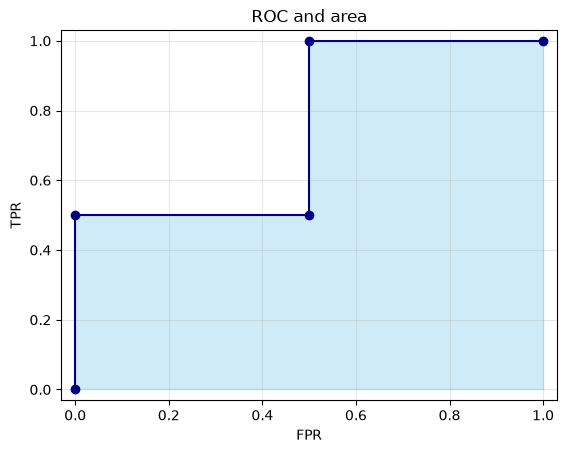

In [9]:
from sklearn.metrics import auc, roc_auc_score
import matplotlib.pyplot as plt

roc_truth = np.array([1, -1, 1, -1])
roc_scores = np.array([0.9, 0.6, 0.4, 0.1])
roc_matrices = {}
for threshold in [0.5, 0.3]:
    pred = np.where(roc_scores >= threshold, 1, -1)
    cm = confusion_matrix(roc_truth, pred, labels=[-1, 1])
    tn, fp, fn, tp = cm.ravel()
    roc_matrices[threshold] = cm.tolist()
    f1_at_threshold = 2 * tp / (2 * tp + fp + fn)
    print("임계값", threshold, "혼동행렬", cm.tolist(),
          "TPR", tp / (tp + fn), "FPR", fp / (fp + tn),
          "정확도", (pred == roc_truth).mean(), "F1", f1_at_threshold)
fpr, tpr, thresholds = roc_curve(roc_truth, roc_scores, pos_label=1, drop_intermediate=False)
print("ROC 좌표 (FPR, TPR):", list(zip(fpr.round(2).tolist(), tpr.round(2).tolist())))
# roc_auc_score의 1을 양성으로 명시합니다. 양쪽 클래스가 모두 있을 때만 계산합니다.
binary_truth = (roc_truth == 1).astype(int)
roc_area = auc(fpr, tpr)
rank_area = roc_auc_score(binary_truth, roc_scores)
print("사다리꼴 면적:", roc_area, "양성 점수의 ROC-AUC:", rank_area)
assert np.isclose(roc_area, 0.75) and np.isclose(rank_area, roc_area)

# 점수와 임계값을 함께 1만큼 옮기면 판정은 같습니다. 점수만 옮기면 달라질 수 있습니다.
shifted_scores = roc_scores + 1
original_pred = np.where(roc_scores >= 0.5, 1, -1)
shifted_pred = np.where(shifted_scores >= 1.5, 1, -1)
fixed_threshold_pred = np.where(shifted_scores >= 0.5, 1, -1)
print("원래 판정:", original_pred.tolist(), "함께 이동:", shifted_pred.tolist(),
      "임계값을 그대로 둠:", fixed_threshold_pred.tolist())
assert np.array_equal(original_pred, shifted_pred)
assert not np.array_equal(original_pred, fixed_threshold_pred)
assert np.isclose(roc_auc_score(binary_truth, shifted_scores), rank_area)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, marker="o", color="navy")
ax.fill_between(fpr, tpr, 0, color="skyblue", alpha=0.4)
ax.set(xlabel="FPR", ylabel="TPR", title="ROC and area", xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
ax.grid(True, alpha=0.3)
plt.show()

ROC는 임계값에 따른 FPR과 TPR을 함께 보여 줍니다. 위 표에서 양성 점수 0.9는 두 음성 점수보다 높고, 양성 점수 0.4는 두 음성 점수 중 0.1보다만 높습니다. 따라서 네 양성–음성 쌍 중 세 쌍을 올바르게 정렬해 AUC는 $3/4=0.75$입니다. ROC에서 폭이 $1/2$인 첫 가로 구간은 높이 $1/2$이므로 면적 $1/4$, 다음 가로 구간은 높이 1이므로 면적 $1/2$입니다. 세로 구간은 폭이 0이어서 더하지 않습니다. 전체 면적은 $1/4+1/2=3/4$로 위 쌍 계산과 같습니다. 이 네 행만으로 실제 모델의 성능을 주장할 수는 없습니다.

AUC는 여러 임계값에 걸친 **점수 순서**, 정확도와 F1은 **정한 한 임계값의 판정**을 봅니다. 위 표에서 임계값만 0.5에서 0.3으로 바꾸면 F1은 바뀌지만 점수 순서는 그대로여서 AUC는 바뀌지 않습니다. 점수와 임계값을 함께 같은 만큼 올리면 판정이 같지만, 임계값을 그대로 두고 점수만 올리면 판정이 바뀔 수 있습니다. 순서가 그대로인 점수 변환은 AUC를 보존하지만, 이것만으로 점수가 잘 보정된 확률인지 알 수 없습니다.

이진 평가에서 AUC 0.5는 해당 자료의 쌍 순위 점수가 절반이라는 뜻입니다. ROC의 모든 점이 대각선 위에 있다거나 점수가 무작위로 만들어졌다는 증거는 아닙니다. AUC가 0.5보다 작을 수도 있습니다. 실제 양성 또는 음성 중 하나가 전혀 없으면 비교할 양성–음성 쌍과 ROC의 한 축이 없어 AUC는 정의되지 않습니다. 최종 테스트를 열기 전에 후보와 임계값을 정하고, 정해진 검증 결과로 선택하세요.

## 자료 출처와 다음 연결

- [KOAI/IOAI 출제 기준](https://kitpa.org/koai/syllabus): 국내 페이지는 IOAI 2026 기준으로 표시합니다. 이 단원은 전처리·평가·혼동행렬의 선수 연결에 초점을 둡니다.
- [IOAI 2025 Antique 공식 문제](https://raw.githubusercontent.com/IOAI-official/IOAI-2025/main/Individual-Contest/Antique/Antique.ipynb): 미상 0과 -1/+1의 의미. 국제 문제를 교육에 옮긴 것으로 중등 기출이 아닙니다.
- [IOAI 2026 Robot Chasing 공식 문제](https://raw.githubusercontent.com/IOAI-official/IOAI-2026/main/Individual-Contest/2_Robot_Chasing/statement.md): 입력·출력, 공개/숨은 라벨, 로봇별 평균의 계약. 국제 문제를 교육에 옮긴 것으로 중등 기출이 아닙니다.
- [scikit-learn: ROC-AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), [사다리꼴 면적](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html): 양성 점수와 면적 계산.
- [scikit-learn: 데이터 누수와 전처리](https://scikit-learn.org/stable/common_pitfalls.html), [정밀도·재현율과 zero_division](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html): 훈련 전용 fit과 0분모의 라이브러리 정책.

3~9주차에 회귀·분류·이미지·언어 자료로 옮겨갈 때도, 새로운 입력의 제공 시점 → 분할 단위 → 훈련에만 fit → 허용된 정답 → 평가 단위 순서로 다시 질문하세요. 교안 실행과 학생의 독립 성취는 서로 다른 확인입니다.